In [ ]:
!pip install thefittest==0.3.0

In [1]:
!pip install matplotlib networkx



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


## Using Genetic Programming for Symbolic Regression

$$y = \frac{1}{2} x \sin(3 x)$$

In [2]:
import numpy as np


def problem(x):
    return np.sin(x[:,0]*3)*x[:,0]*0.5

0-th iteration with the best fitness = 0.8402687518211717
10-th iteration with the best fitness = 0.654902079045495
20-th iteration with the best fitness = 0.5429500452276517
30-th iteration with the best fitness = 0.5233197707265815
40-th iteration with the best fitness = 0.5040442569611662
50-th iteration with the best fitness = 0.5029130817044493
60-th iteration with the best fitness = 0.5002075514264978
70-th iteration with the best fitness = 0.5002067409842819
80-th iteration with the best fitness = 0.12594207102045107
90-th iteration with the best fitness = 0.12594207102045107
100-th iteration with the best fitness = 0.1243437533981372
110-th iteration with the best fitness = 0.10392186916360437
120-th iteration with the best fitness = 0.06384758573968552
130-th iteration with the best fitness = 0.001285106486956443
140-th iteration with the best fitness = 0.001285106486956443
150-th iteration with the best fitness = 0.0012851064869564245
160-th iteration with the best fitness = 

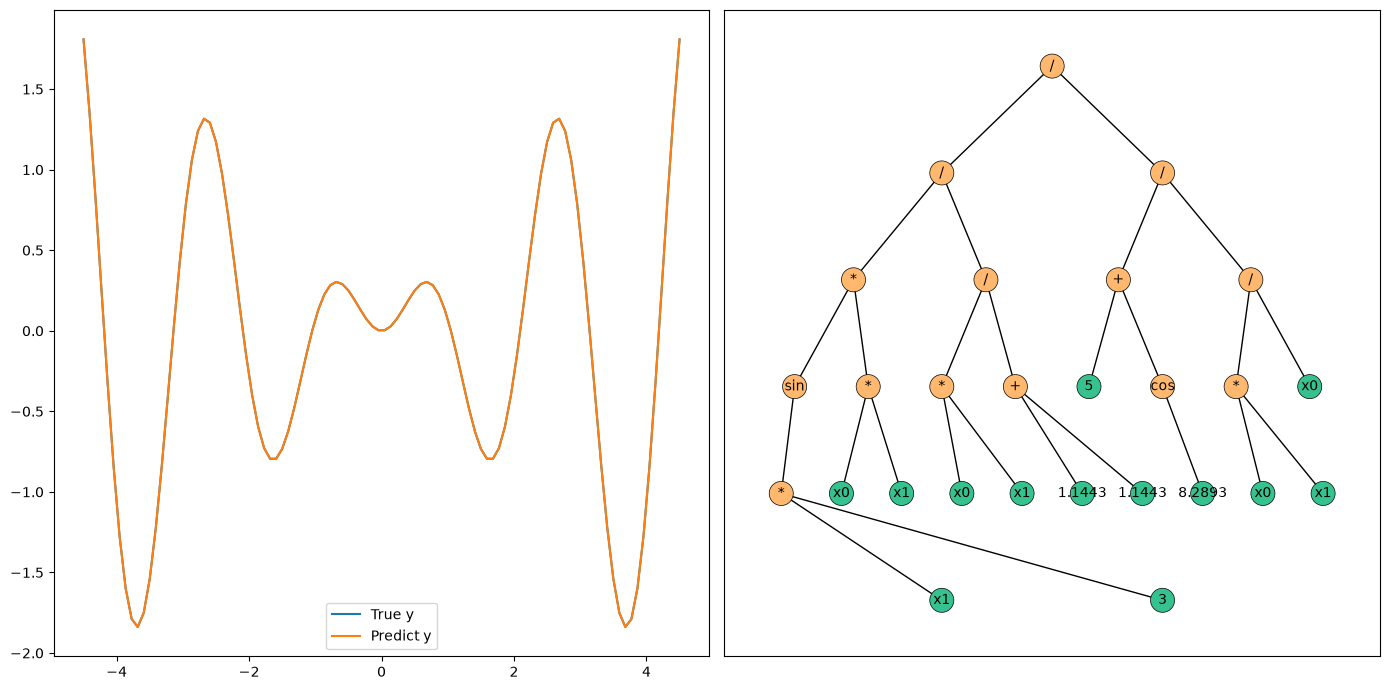

In [3]:
import matplotlib.pyplot as plt

from thefittest.regressors import GeneticProgrammingRegressor
from thefittest.optimizers import PDPGP

n_dimension = 2
left_border = -4.5
right_border = 4.5
sample_size = 100


X = np.array([np.linspace(left_border, right_border, sample_size)
              for _ in range(n_dimension)]).T
y = problem(X)

model = GeneticProgrammingRegressor(n_iter=500,
                                    pop_size=1000,
                                    optimizer=PDPGP,
                                    optimizer_args={"show_progress_each": 10,
                                                    "max_level": 5})

model.fit(X, y)
predict = model.predict(X)

tree = model.get_tree()
print('The fittest individ:', tree)

fig, ax = plt.subplots(figsize=(14, 7), ncols=2, nrows=1)

ax[0].plot(X[:,0], y, label = "True y")
ax[0].plot(X[:,0], predict, label = "Predict y")
ax[0].legend()

tree.plot(ax=ax[1])

plt.tight_layout()
plt.show()

## Multiobjective symbolic regression


In [20]:
from thefittest.optimizers import NSGPII

pareto_model = GeneticProgrammingRegressor(
    n_iter=500,
    pop_size=1000,
    optimizer=NSGPII,  # Optimize two objectives: prediction error and tree complexity.
    complexity="n_nodes",  # Use the number of tree nodes as the second objective.   
    optimizer_args={"show_progress_each": 10, "max_level": 7},
)
pareto_model.fit(X, y)
front = pareto_model.get_pareto_front()

0-th iteration with Pareto front size = 4; best objectives = [f1=0.880053, f2=2]
10-th iteration with Pareto front size = 10; best objectives = [f1=0.762066, f2=1]
20-th iteration with Pareto front size = 3; best objectives = [f1=0.629112, f2=1]
30-th iteration with Pareto front size = 4; best objectives = [f1=0.629112, f2=1]
40-th iteration with Pareto front size = 6; best objectives = [f1=0.605225, f2=1]
50-th iteration with Pareto front size = 10; best objectives = [f1=0.515617, f2=1]
60-th iteration with Pareto front size = 16; best objectives = [f1=0.446274, f2=1]
70-th iteration with Pareto front size = 10; best objectives = [f1=0.392419, f2=1]
80-th iteration with Pareto front size = 15; best objectives = [f1=0.373179, f2=1]
90-th iteration with Pareto front size = 15; best objectives = [f1=0.174863, f2=1]
100-th iteration with Pareto front size = 21; best objectives = [f1=0.0982189, f2=1]
110-th iteration with Pareto front size = 31; best objectives = [f1=0.0980845, f2=1]
120-t

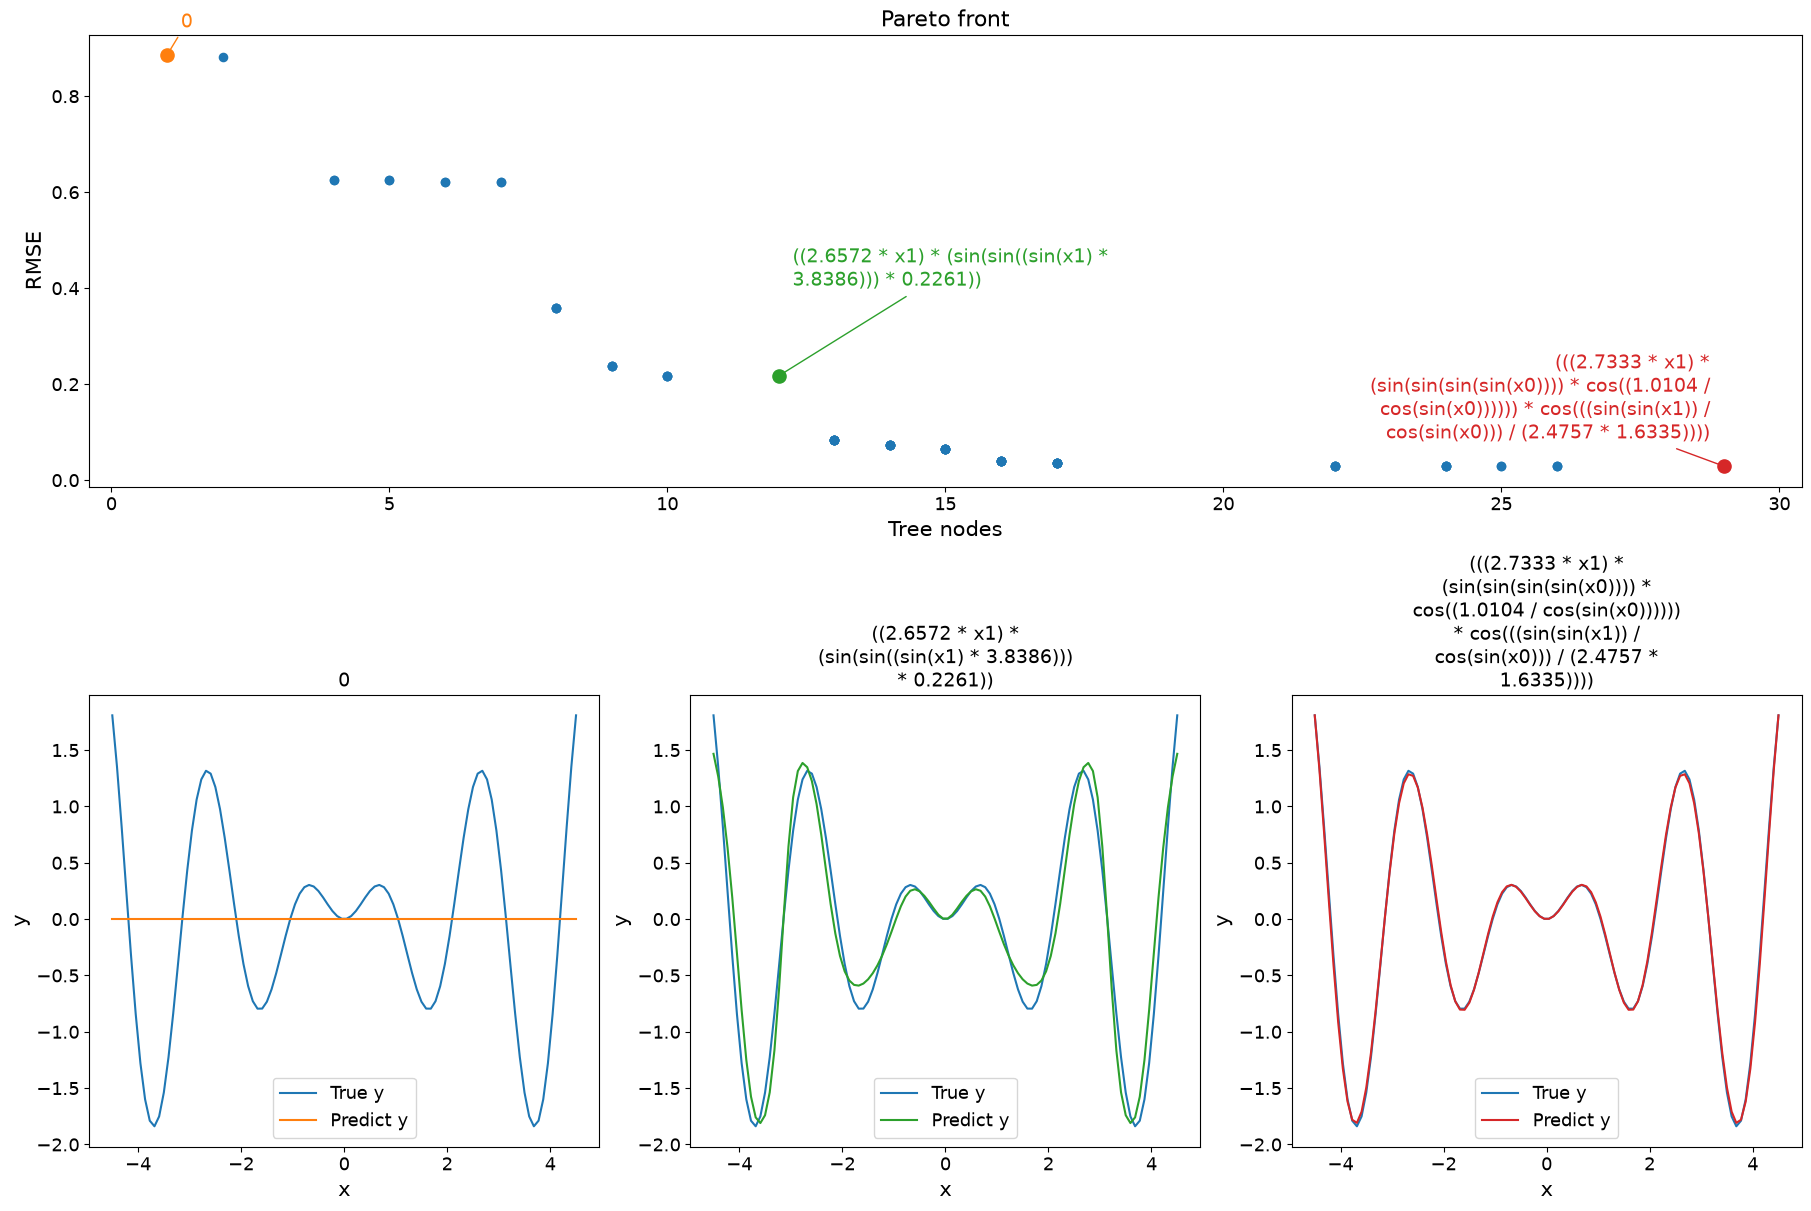

In [21]:
from textwrap import fill

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
})

errors, sizes = front["fitness"].T
_, unique = np.unique(front["fitness"], axis=0, return_index=True)
order = unique[np.argsort(sizes[unique])]
selected = order[np.linspace(0, len(order) - 1, min(3, len(order)), dtype=int)]

fig = plt.figure(figsize=(18, 12), layout="constrained")
grid = fig.add_gridspec(2, len(selected))
ax = fig.add_subplot(grid[0, :])
ax.scatter(sizes, errors, s=35)
ax.set(xlabel="Tree nodes", ylabel="RMSE", title="Pareto front")

active = pareto_model.selected_tree_index_
for column, index in enumerate(selected):
    formula = str(front["phenotype"][index])
    color = f"C{column + 1}"
    right = column == len(selected) - 1

    ax.scatter(sizes[index], errors[index], color=color, s=90)
    ax.annotate(
        fill(formula, 40),
        (sizes[index], errors[index]),
        xytext=(-10 if right else 10, 20 + 45 * (column % 2)),
        textcoords="offset points",
        ha="right" if right else "left",
        color=color,
        fontsize=14,
        arrowprops={"arrowstyle": "-", "color": color},
    )

    prediction_ax = fig.add_subplot(grid[1, column])
    pareto_model.select_tree(int(index))
    prediction_ax.plot(X[:, 0], y, label="True y")
    prediction_ax.plot(
        X[:, 0], pareto_model.predict(X), color=color, label="Predict y"
    )
    prediction_ax.set(xlabel="x", ylabel="y")
    prediction_ax.set_title(fill(formula, 30), fontsize=14)
    prediction_ax.legend()

pareto_model.select_tree(active)
plt.show()

## Using Genetic Programming for Classification

In [22]:
from thefittest.optimizers import GeneticProgramming
from thefittest.benchmarks import BreastCancerDataset
from thefittest.classifiers import GeneticProgrammingClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import minmax_scale
from sklearn.metrics import confusion_matrix, f1_score

# Load the Breast Cancer dataset
data = BreastCancerDataset()
X = data.get_X()
y = data.get_y()

# Scale features to the [0, 1] range
X_scaled = minmax_scale(X)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.1)

# Initialize the GeneticProgrammingClassifier with GeneticProgramming as the optimizer
model = GeneticProgrammingClassifier(
    n_iter=150,
    pop_size=500,
    optimizer=GeneticProgramming,
    optimizer_args = {"selection": "tournament_3",
                      'show_progress_each': 1,
                      "max_level": 17,
                      },
    use_fitness_cache=True
)

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
predict = model.predict(X_test)

# Evaluate the model
print("confusion_matrix: \n", confusion_matrix(y_test, predict))
print("f1_score: \n", f1_score(y_test, predict, average="macro"))

print(model.get_tree())

0-th iteration with the best fitness = 0.5071375910938841
1-th iteration with the best fitness = 0.4677468367307938
2-th iteration with the best fitness = 0.4544696952165707
3-th iteration with the best fitness = 0.27849924709249657
4-th iteration with the best fitness = 0.2239433802613076
5-th iteration with the best fitness = 0.2239433802613076
6-th iteration with the best fitness = 0.2204568831003379
7-th iteration with the best fitness = 0.21113080766005593
8-th iteration with the best fitness = 0.18793525443609893
9-th iteration with the best fitness = 0.18793525443609893
10-th iteration with the best fitness = 0.18793525443609893
11-th iteration with the best fitness = 0.1864105035954009
12-th iteration with the best fitness = 0.17709354820971232
13-th iteration with the best fitness = 0.17709354820971232
14-th iteration with the best fitness = 0.16906517981715571
15-th iteration with the best fitness = 0.16558764029489167
16-th iteration with the best fitness = 0.160438830520616

## Genetic Programming with custom universal set

In [23]:
from thefittest.utils import create_operator
from thefittest.base import UniversalSet, TerminalNode, FunctionalNode, EphemeralNode
from thefittest.optimizers import GeneticProgramming
import numpy as np


# =========================================================
# 1. User-defined functions (primitives)
# =========================================================
# The user defines custom functions that will be used
# by Genetic Programming as functional primitives.

def add(a, b):
    return a + b

def sub(a, b):
    return a - b

def mul(a, b):
    return a * b

def save_div(a, b):
    # Safe division to avoid division by zero
    if b == 0:
        return 1
    return a / b


# =========================================================
# 2. Terminal variables (input values)
# =========================================================
# These values are substituted into the generated expressions

x_1 = 3
x_2 = 5


# =========================================================
# 3. FunctionalNode — function primitives
# =========================================================
# The user:
#  - creates operators using create_operator
#  - wraps them with FunctionalNode
#
# create_operator defines:
#   - a string template (phenotype representation)
#   - function name
#   - operator symbol
#   - the actual Python function

functional_set = (
    FunctionalNode(create_operator("({} + {})", "add", "+", add)),
    FunctionalNode(create_operator("({} - {})", "sub", "-", sub)),
    FunctionalNode(create_operator("({} * {})", "mul", "*", mul)),
    FunctionalNode(create_operator("({} / {})", "div", "/", save_div)),
)


# =========================================================
# 4. TerminalNode and EphemeralNode — terminal primitives
# =========================================================
# TerminalNode:
#   - used for variables and fixed constants
#
# EphemeralNode:
#   - used for ephemeral (random) constants
#   - a new value is generated for each individual

terminal_set = (
    TerminalNode(x_1, "x_1"),
    TerminalNode(x_2, "x_2"),
    EphemeralNode(lambda: round(np.random.uniform(-10, 10), 2)),
)


# =========================================================
# 5. UniversalSet — universal primitive set
# =========================================================
# UniversalSet combines:
#   - functional primitives (functional_set)
#   - terminal primitives (terminal_set)
#
# GP uses this set to build expression trees

uniset = UniversalSet(functional_set, terminal_set)


# =========================================================
# 6. Fitness function
# =========================================================
# IMPORTANT:
#  - receives a sequence of individuals
#  - must return a numpy array of floats
#
# Each individual:
#  - is callable: individual()
#  - returns the evaluated expression value

def fitness_function(individuals):
    fitness = []

    for individual in individuals:
        values = individual()

        # Target function to be approximated
        target = 3 * (x_1 * x_1 + x_2) * (x_1 - 0.5 / x_2) - 3.53

        # Minimize absolute error
        fitness.append(abs(target - values))

    return np.array(fitness, dtype=float)


# =========================================================
# 7. GeneticProgramming initialization
# =========================================================
# Key parameters:
#  - fitness function
#  - universal set
#  - evolution settings

gp = GeneticProgramming(
    fitness_function=fitness_function,
    uniset=uniset,
    iters=100,
    pop_size=500,
    show_progress_each=10,
    selection="tournament_3",
    minimization=True,
    max_level=3,
)


# =========================================================
# 8. Run the evolution process
# =========================================================
gp.fit()


# =========================================================
# 9. Retrieve the best individual
# =========================================================
fittest = gp.get_fittest()

# Phenotype is a human-readable mathematical expression
print(fittest["phenotype"])


0-th iteration with the best fitness = 1.9366666666666674
10-th iteration with the best fitness = 0.04999999999999716
20-th iteration with the best fitness = 0.007681751824819116
30-th iteration with the best fitness = 0.0032671532846819673
40-th iteration with the best fitness = 0.0032671532846819673
50-th iteration with the best fitness = 0.0032671532846819673
60-th iteration with the best fitness = 0.0032671532846819673
70-th iteration with the best fitness = 0.0032671532846819673
80-th iteration with the best fitness = 0.0032671532846819673
90-th iteration with the best fitness = 7.68472906287343e-05
(((2.87 - x_2) / (4.22 + 7.96)) - ((x_1 - 7.96) * (x_1 * 7.96)))
